<a href="https://colab.research.google.com/github/mauronohara1/TP_LABO/blob/main/02_exploracion_y_analisis_spotify.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evolución de la música en Spotify (1921–2020)

**TP Grupal · Laboratorio de Métodos Cuantitativos · FCE UBA · 2C 2026**

**Integrantes:** _completar_

**Dataset:** [Spotify Dataset 1921–2020, 600k+ Tracks](https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-19212020-600k-tracks) (Kaggle, usuario *yamaerenay*). Usamos el archivo `tracks.csv`, que tiene una fila por canción con su fecha de lanzamiento y sus características de audio.

### Uso de IA
Las celdas marcadas con **[Asistido por IA]** se armaron con ayuda de Claude, usando un proyecto que tenía como contexto las pautas del TP.
Prompt utilizado: «como puedo explorar el dataset»

## 3.1 Carga y exploración inicial

### a) Carga del dataset · [Asistido por IA]

Descargamos el dataset directamente desde Kaggle con la librería `kagglehub`. Así cualquiera puede volver a correr el notebook sin subir archivos a mano. No hace falta cuenta de Kaggle porque el dataset es público.

> Si la descarga falla, se puede bajar el ZIP desde la página de Kaggle, subir `tracks.csv` a Colab (ícono de carpeta a la izquierda) y cargarlo con `pd.read_csv("tracks.csv")`.

In [35]:
%pip install -q kagglehub

In [36]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

# Descarga el dataset y devuelve la carpeta donde quedaron los archivos
path = kagglehub.dataset_download("yamaerenay/spotify-dataset-19212020-600k-tracks")
print("Archivos descargados:", os.listdir(path))

# Cargamos las canciones en un DataFrame
df = pd.read_csv(os.path.join(path, "tracks.csv"))

Using Colab cache for faster access to the 'spotify-dataset-19212020-600k-tracks' dataset.
Archivos descargados: ['dict_artists.json', 'artists.csv', 'tracks.csv']


#### Primeras y últimas filas

Miramos el principio y el final de la tabla para ver cómo vienen los datos: qué tiene cada columna, ejemplos de valores y si hay algo raro a simple vista.

In [37]:
display(df.head())
display(df.tail())

,id,name,popularity,duration_ms,explicit,artists,id_artists,release_date,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,35iwgR4jXetI318WEWsa1Q,Carve,6,126903,0,['Uli'],['45tIt06XoI0Iio4LBEVpls'],1922-02-22,0.645,0.4450,0,-13.338,1,0.4510,0.674,0.7440,0.151,0.127,104.851,3
1,021ht4sdgPcrDgSk7JTbKY,Capítulo 2.16 - Banquero Anarquista,0,98200,0,['Fernando Pessoa'],['14jtPCOoNZwquk5wd9DxrY'],1922-06-01,0.695,0.2630,0,-22.136,1,0.9570,0.797,0.0000,0.148,0.655,102.009,1
2,07A5yehtSnoedViJAZkNnc,Vivo para Quererte - Remasterizado,0,181640,0,['Ignacio Corsini'],['5LiOoJbxVSAMkBS2fUm3X2'],1922-03-21,0.434,0.1770,1,-21.180,1,0.0512,0.994,0.0218,0.212,0.457,130.418,5
3,08FmqUhxtyLTn6pAh6bk45,El Prisionero - Remasterizado,0,176907,0,['Ignacio Corsini'],['5LiOoJbxVSAMkBS2fUm3X2'],1922-03-21,0.321,0.0946,7,-27.961,1,0.0504,0.995,0.9180,0.104,0.397,169.980,3
4,08y9GfoqCWfOGsKdwojr5e,Lady of the Evening,0,163080,0,['Dick Haymes'],['3BiJGZsyX9sJchTqcSA7Su'],1922,0.402,0.1580,3,-16.900,0,0.0390,0.989,0.1300,0.311,0.196,103.220,4


,id,name,popularity,duration_ms,explicit,artists,id_artists,release_date,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
586667,5rgu12WBIHQtvej2MdHSH0,云与海,50,258267,0,['阿YueYue'],['1QLBXKM5GCpyQQSVMNZqrZ'],2020-09-26,0.560,0.518,0,-7.471,0,0.0292,0.785,0.000000,0.0648,0.2110,131.896,4
586668,0NuWgxEp51CutD2pJoF4OM,blind,72,153293,0,['ROLE MODEL'],['1dy5WNgIKQU6ezkpZs4y8z'],2020-10-21,0.765,0.663,0,-5.223,1,0.0652,0.141,0.000297,0.0924,0.6860,150.091,4
586669,27Y1N4Q4U3EfDU5Ubw8ws2,What They'll Say About Us,70,187601,0,['FINNEAS'],['37M5pPGs6V1fchFJSgCguX'],2020-09-02,0.535,0.314,7,-12.823,0,0.0408,0.895,0.000150,0.0874,0.0663,145.095,4
586670,45XJsGpFTyzbzeWK8VzR8S,A Day At A Time,58,142003,0,"['Gentle Bones', 'Clara Benin']","['4jGPdu95icCKVF31CcFKbS', '5ebPSE9YI5aLeZ1Z2g...",2021-03-05,0.696,0.615,10,-6.212,1,0.0345,0.206,0.000003,0.3050,0.4380,90.029,4
586671,5Ocn6dZ3BJFPWh4ylwFXtn,Mar de Emociones,38,214360,0,['Afrosound'],['0i4Qda0k4nf7jnNHmSNpYv'],2015-07-01,0.686,0.723,6,-7.067,1,0.0363,0.105,0.000000,0.2640,0.9750,112.204,4


### b) Estructura: dimensiones, columnas y tipos de dato · [Asistido por IA]

Vemos cuántas filas (canciones) y columnas tiene el dataset, y de qué tipo es cada columna. Detalles a tener en cuenta:
- `release_date` es **texto**, no fecha. Hay que convertirla para trabajar con años.
- `artists` es un texto con forma de lista, por ejemplo `"['Uli']"`.
- `explicit` y `mode` son 0/1, y `key` es un número de 0 a 11 que representa la nota (0 = Do).

In [38]:
print("Filas (canciones):", df.shape[0])
print("Columnas:", df.shape[1])
df.dtypes

Filas (canciones): 586672
Columnas: 20


,0
id,object
name,object
popularity,int64
duration_ms,int64
explicit,int64
artists,object
id_artists,object
release_date,object
danceability,float64
energy,float64


#### Cobertura temporal

`release_date` no tiene siempre la misma precisión: algunas canciones solo tienen el año, otras año y mes, y otras la fecha completa. Primero contamos cuántas hay de cada tipo según la cantidad de caracteres. Después tomamos los primeros 4 caracteres para obtener el año y ver qué período cubre el dataset.

Por ahora el año se calcula solo para explorar. La columna definitiva se crea en la sección 3.3 (transformaciones).

El dataset **no tiene cobertura geográfica**: no incluye país de origen de las canciones ni de los artistas.

In [39]:
# 4 caracteres = solo año, 7 = año y mes, 10 = fecha completa
precision = df["release_date"].str.len().map({4: "solo año", 7: "año y mes", 10: "fecha completa"})
print(precision.value_counts(dropna=False))

# Año de lanzamiento (temporal, solo para explorar)
anio = df["release_date"].str[:4].astype(int)
print()
print("Año mínimo:", anio.min())
print("Año máximo:", anio.max())

release_date
fecha completa    448081
solo año          136489
año y mes           2102
Name: count, dtype: int64

Año mínimo: 1900
Año máximo: 2021


Contamos las canciones por década para ver si el dataset está balanceado en el tiempo.

In [40]:
decada = (anio // 10) * 10
decada.value_counts().sort_index().rename("canciones")

,canciones
release_date,
1900,1
1920,7610
1930,13037
1940,18042
1950,35370
1960,47270
1970,61841
1980,82322
1990,108875


Lo graficamos por año. Si las primeras décadas tienen muy pocas canciones, sus promedios van a ser menos confiables y hay que tenerlo en cuenta al sacar conclusiones.

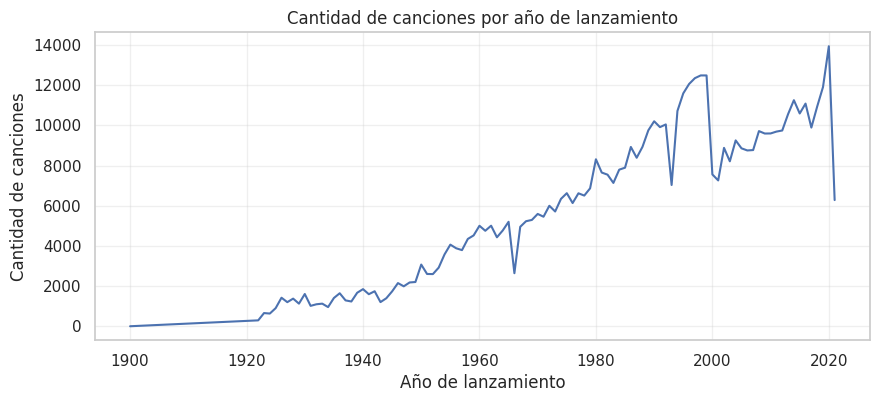

In [41]:
anio.value_counts().sort_index().plot(figsize=(10, 4))
plt.title("Cantidad de canciones por año de lanzamiento")
plt.xlabel("Año de lanzamiento")
plt.ylabel("Cantidad de canciones")
plt.grid(alpha=0.3)
plt.show()

### c) Calidad de los datos · [Asistido por IA]

#### Valores nulos
Contamos cuántos valores faltan en cada columna.

In [42]:
df.isnull().sum()

,0
id,0
name,71
popularity,0
duration_ms,0
explicit,0
artists,0
id_artists,0
release_date,0
danceability,0
energy,0


#### Duplicados
Los revisamos en tres niveles:
1. **Filas idénticas**: la misma fila repetida tal cual.
2. **IDs repetidos**: el mismo identificador de Spotify más de una vez.
3. **Misma canción y artista**: mismo `name` y `artists` con distinto `id`. Suelen ser reediciones, remasters o compilados. Importan para nuestra pregunta, porque una canción de 1965 reeditada en 2010 aparece con fecha de 2010.

In [43]:
print("Filas completamente duplicadas:", df.duplicated().sum())
print("IDs repetidos:", df["id"].duplicated().sum())
print("Misma canción y artista repetidos:", df.duplicated(subset=["name", "artists"]).sum())

Filas completamente duplicadas: 0
IDs repetidos: 0
Misma canción y artista repetidos: 60062


In [44]:
# Las 5 combinaciones canción + artista que más se repiten
repetidas = df[df.duplicated(subset=["name", "artists"], keep=False)]
repetidas.groupby(["name", "artists"]).size().sort_values(ascending=False).head(5)

,,0
name,artists,
Year 3000,['Busted'],54
Hold On,['Justin Bieber'],47
Anyone,['Justin Bieber'],44
No Es Justo,"['J Balvin', 'Zion & Lennox']",42
Azul,['J Balvin'],42


#### Estadísticas descriptivas
Resumen de las columnas numéricas: promedio, desvío, mínimo, máximo y cuartiles. Lo transponemos (`.T`) para que cada variable quede en una fila y se lea más fácil.

In [45]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
popularity,586672.0,27.57,18.37,0.0,13.00,27.00,41.00,100.00
duration_ms,586672.0,230051.17,126526.09,3344.0,175093.00,214893.00,263867.00,5621218.00
explicit,586672.0,0.04,0.21,0.0,0.00,0.00,0.00,1.00
danceability,586672.0,0.56,0.17,0.0,0.45,0.58,0.69,0.99
energy,586672.0,0.54,0.25,0.0,0.34,0.55,0.75,1.00
key,586672.0,5.22,3.52,0.0,2.00,5.00,8.00,11.00
loudness,586672.0,-10.21,5.09,-60.0,-12.89,-9.24,-6.48,5.38
mode,586672.0,0.66,0.47,0.0,0.00,1.00,1.00,1.00
speechiness,586672.0,0.10,0.18,0.0,0.03,0.04,0.08,0.97
acousticness,586672.0,0.45,0.35,0.0,0.10,0.42,0.78,1.00


#### Valores sospechosos
A partir de lo que se ve en `describe()`, revisamos casos que pueden ser errores o que no son música:
- `tempo = 0` o `time_signature = 0`: Spotify no pudo medir el ritmo.
- `speechiness > 0.66`: según Spotify, es audio casi todo hablado (audiolibros, poesía, discursos).
- Duraciones extremas.

In [46]:
print("Canciones con tempo = 0:", (df["tempo"] == 0).sum())
print("Canciones con time_signature = 0:", (df["time_signature"] == 0).sum())
print("Canciones con popularidad = 0:", (df["popularity"] == 0).sum())
print("Grabaciones casi solo habladas (speechiness > 0.66):", (df["speechiness"] > 0.66).sum())
print("Canciones de más de 20 minutos:", (df["duration_ms"] > 20 * 60 * 1000).sum())
print("Canciones de menos de 30 segundos:", (df["duration_ms"] < 30 * 1000).sum())

Canciones con tempo = 0: 328
Canciones con time_signature = 0: 337
Canciones con popularidad = 0: 44690
Grabaciones casi solo habladas (speechiness > 0.66): 22598
Canciones de más de 20 minutos: 1089
Canciones de menos de 30 segundos: 228


In [47]:
# Ejemplos de las grabaciones más "habladas": ¿son música o no?
(df[df["speechiness"] > 0.66]
   .sort_values("speechiness", ascending=False)
   [["name", "artists", "release_date", "speechiness"]]
   .head(10))

,name,artists,release_date,speechiness
482360,"Wer die Nachtigall stört ..., Kapitel 6","['Harper Lee', 'Eva Mattes']",1960,0.971
482422,"Wer die Nachtigall stört ..., Kapitel 98","['Harper Lee', 'Eva Mattes']",1960,0.971
324123,"Wer die Nachtigall stört ..., Kapitel 1","['Harper Lee', 'Eva Mattes']",1960,0.971
25842,Kapitel 16 - Der alte Mann und das Meer - Erzä...,"['Ernest Hemingway', 'Christian Brückner']",1952,0.970
25839,Kapitel 15 - Der alte Mann und das Meer - Erzä...,"['Ernest Hemingway', 'Christian Brückner']",1952,0.970
482383,"Wer die Nachtigall stört ..., Kapitel 12","['Harper Lee', 'Eva Mattes']",1960,0.970
482472,"Wer die Nachtigall stört ..., Kapitel 147","['Harper Lee', 'Eva Mattes']",1960,0.970
493349,"Wer die Nachtigall stört ..., Kapitel 105","['Harper Lee', 'Eva Mattes']",1960,0.970
493342,"Wer die Nachtigall stört ..., Kapitel 95","['Harper Lee', 'Eva Mattes']",1960,0.970
482444,"Wer die Nachtigall stört ..., Kapitel 128","['Harper Lee', 'Eva Mattes']",1960,0.970


### Hallazgos de la exploración (completar)

*Las pautas piden comentar los hallazgos antes de continuar. Completen con los números que les dio cada celda:*

- **Tamaño:** el dataset tiene ___ canciones y ___ columnas.
- **Cobertura temporal:** va de ___ a ___. Las décadas con menos canciones son ___, así que sus promedios son menos confiables.
- **Fechas:** ___ % de las canciones solo tienen el año, por eso trabajamos con el año y no con la fecha completa.
- **Nulos:** ___ (¿en qué columnas? ¿afectan a las variables que vamos a usar?).
- **Duplicados:** ___ canciones aparecen repetidas con el mismo nombre y artista (posibles reediciones).
- **Valores raros:** ___ grabaciones habladas, ___ con tempo 0, ...
- **Decisiones para la sección 3.3:** qué vamos a filtrar o transformar a partir de esto.

## 3.2 Pregunta de investigación · [Asistido por IA]

A partir de la exploración del dataset histórico, planteamos la siguiente pregunta central:

a) **¿Cuál es la pregunta?**
*¿Cómo han evolucionado las características principales de audio (como la energía, la bailabilidad y la acústica) de las canciones a lo largo de las décadas, y de qué manera reflejan los cambios en las preferencias de consumo masivo en la plataforma?*

b) **¿Por qué vale la pena responderla?**
Permite comprender la transformación histórica de la industria musical y detectar si los oyentes actuales prefieren patrones sonoros radicalmente distintos a los de principios del siglo XX (por ejemplo, el paso de la música acústica y orquestal a producciones electrónicas más enérgicas y bailables).

c) **¿Qué respuesta encontraron?**
*(Este apartado se completará al finalizar el análisis cuantitativo y la visualización de los datos).*


### 3.3 Transformaciones y resumen estadístico

### a) Transformaciones justificadas

Para poder analizar la evolución temporal de forma correcta, realizamos las siguientes transformaciones:
1. **Extracción y limpieza del año de lanzamiento (`release_date` a `year`):** Como la fecha original tenía formatos mixtos (algunas solo año, otras mes o día), extrajimos los primeros 4 caracteres para construir una variable numérica estricta (`year`) y, a partir de ella, crear una variable de **década** para agrupar las tendencias históricas.
2. **Filtrado de valores anómalos o extremos:** Eliminamos registros con duración cero o pistas habladas extremas (`speechiness > 0.66`) que distorsionan las métricas musicales puras, asegurando que el análisis de preferencias refleje canciones reales.


In [48]:
# ==========================================
# TRANSFORMACIONES JUSTIFICADAS
# ==========================================

# 1. Crear la columna numérica de año y la agrupación por década
df['year'] = pd.to_numeric(df['release_date'].astype(str).str[:4], errors='coerce')
df['decada'] = (df['year'] // 10) * 10

# 2. Filtrar valores nulos en variables clave y descartar audios hablados o duraciones anómalas
df_analisis = df.dropna(subset=['year', 'popularity', 'danceability', 'energy', 'acousticness']).copy()
df_analisis = df_analisis[(df_analisis['speechiness'] <= 0.66) & (df_analisis['duration_ms'] > 30000)]

print(f"Dataset original: {df.shape[0]} filas")
print(f"Dataset limpio para el análisis temporal: {df_analisis.shape[0]} filas")
display(df_analisis[['name', 'artists', 'year', 'decada', 'popularity', 'danceability', 'energy']].head())


Dataset original: 586672 filas
Dataset limpio para el análisis temporal: 563865 filas


,name,artists,year,decada,popularity,danceability,energy
0,Carve,['Uli'],1922,1920,6,0.645,0.4450
2,Vivo para Quererte - Remasterizado,['Ignacio Corsini'],1922,1920,0,0.434,0.1770
3,El Prisionero - Remasterizado,['Ignacio Corsini'],1922,1920,0,0.321,0.0946
4,Lady of the Evening,['Dick Haymes'],1922,1920,0,0.402,0.1580
5,Ave Maria,['Dick Haymes'],1922,1920,0,0.227,0.2610


### b) Estadísticos de resumen agrupados con .groupby()

Agrupamos los datos por **década** para calcular las medias históricas de la energía, la bailabilidad y la popularidad, lo que nos permite identificar los puntos de quiebre en las preferencias musicales a lo largo de los últimos 100 años.


In [49]:
# ==========================================
# ESTADÍSTICOS AGRUPADOS (.groupby)
# ==========================================

# Resumen por década: evolución de atributos de audio y popularidad media
resumen_decadas = df_analisis.groupby('decada').agg(
total_canciones=('popularity', 'count'),
popularidad_promedio=('popularity', 'mean'),
bailabilidad_media=('danceability', 'mean'),
energia_media=('energy', 'mean'),
acustica_media=('acousticness', 'mean')).sort_index()


print("Evolución histórica de atributos musicales por década:")
display(resumen_decadas.round(3))

Evolución histórica de atributos musicales por década:


,total_canciones,popularidad_promedio,bailabilidad_media,energia_media,acustica_media
decada,,,,,
1900,1,19.000,0.659,0.791,0.139
1920,5777,1.415,0.578,0.300,0.951
1930,11298,2.138,0.532,0.312,0.918
1940,17593,1.752,0.472,0.267,0.921
1950,33777,8.666,0.474,0.301,0.847
1960,46206,18.078,0.493,0.405,0.684
1970,58839,24.257,0.517,0.504,0.489
1980,74919,25.468,0.553,0.561,0.386
1990,104512,29.476,0.568,0.579,0.358


## 3.4 Análisis gráfico

Desarrollamos tres gráficos de diferente tipología para visualizar la evolución temporal de las preferencias musicales y su relación interna.


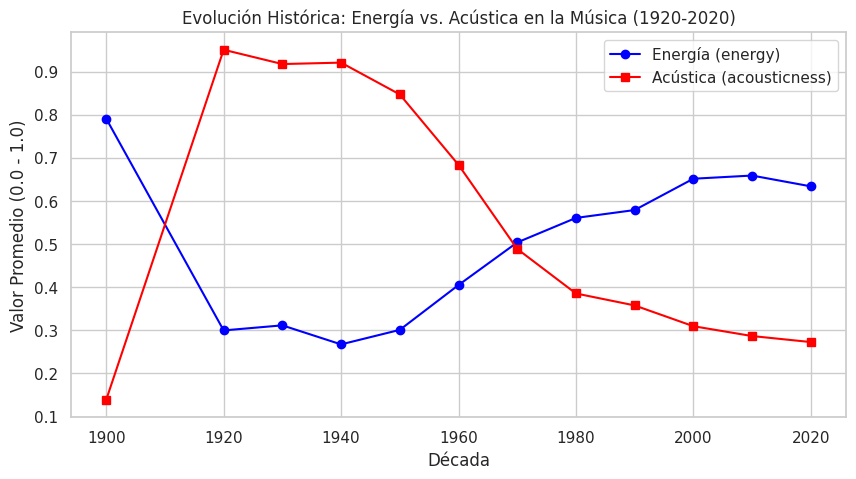

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# ==========================================
# GRÁFICO 1: Evolución temporal (Líneas) de Energía vs Acústica por década
# ==========================================
plt.figure(figsize=(10, 5))
plt.plot(resumen_decadas.index, resumen_decadas['energia_media'], marker='o', label='Energía (energy)', color='blue')
plt.plot(resumen_decadas.index, resumen_decadas['acustica_media'], marker='s', label='Acústica (acousticness)', color='red')
plt.title("Evolución Histórica: Energía vs. Acústica en la Música (1920-2020)")
plt.xlabel("Década")
plt.ylabel("Valor Promedio (0.0 - 1.0)")
plt.legend()
plt.savefig("evolucion_energia_acustica.png", dpi=300, bbox_inches='tight')
plt.show()



Gráfico 2 - Bailabilidad Promedio por Década
Gráfico de barras que compara el nivel medio de bailabilidad (`danceability`) de las canciones a lo largo de las diferentes décadas. Permite observar de forma directa si las preferencias de consumo masivo se inclinaron hacia ritmos más aptos para el baile en determinados períodos históricos.


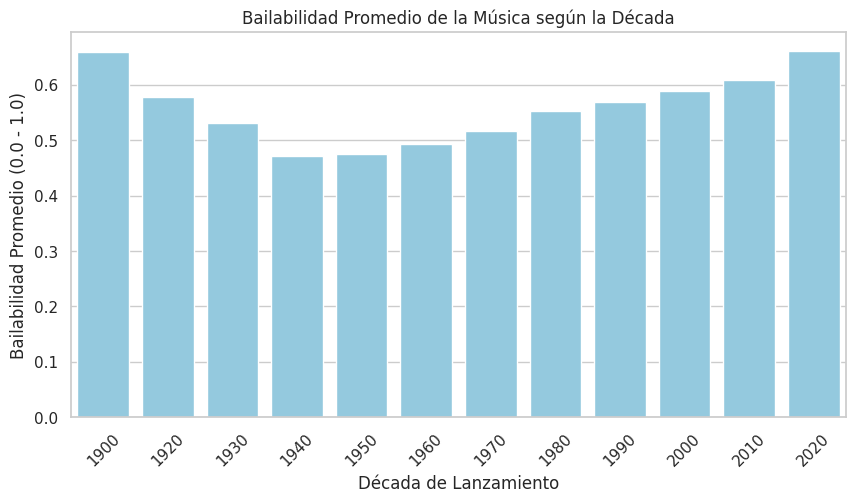

In [56]:
# ==========================================
# GRÁFICO 2: Barras - Bailabilidad Promedio por Década
# ==========================================
plt.figure(figsize=(10, 5))
sns.barplot(x=resumen_decadas.index, y='bailabilidad_media', data=resumen_decadas.reset_index(),color='skyblue')
plt.title("Bailabilidad Promedio de la Música según la Década")
plt.xlabel("Década de Lanzamiento")
plt.ylabel("Bailabilidad Promedio (0.0 - 1.0)")
plt.xticks(rotation=45)
plt.savefig("barras_bailabilidad_decada.png", dpi=300, bbox_inches='tight')
plt.show()


### Distribución de la Popularidad de las Canciones
Histograma que muestra la frecuencia y distribución del puntaje de popularidad (`popularity`) de las canciones en el dataset. Permite observar si la gran mayoría de los temas se concentran en niveles bajos de popularidad o si existe una distribución normal o sesgada hacia los éxitos comerciales.


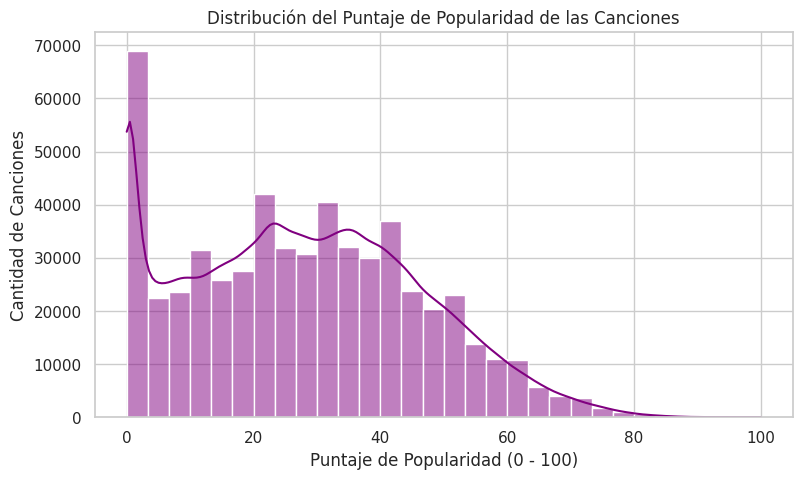

In [52]:
# ==========================================
# GRÁFICO 3: Histograma - Distribución de la Popularidad
# ==========================================
plt.figure(figsize=(9, 5))
sns.histplot(df_analisis['popularity'], bins=30, kde=True, color='purple')
plt.title("Distribución del Puntaje de Popularidad de las Canciones")
plt.xlabel("Puntaje de Popularidad (0 - 100)")
plt.ylabel("Cantidad de Canciones")
plt.savefig("histograma_popularidad.png", dpi=300, bbox_inches='tight')
plt.show()
